# Custom themes

You will build: your own brand theme made from a built-in one, with colours that follow each other, and a
theme kept in a TOML file.

Run it from this folder with ``python custom_themes.py``, or open ``custom_themes.ipynb``.

In [1]:
import svgwriter as svg

The diagram from the previous example, drawn only with roles.

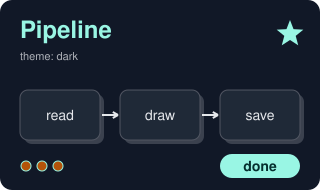

In [2]:
WIDTH, HEIGHT = 320, 190
SHADOW = 4


def card(theme: svg.Theme | str = "light") -> svg.Document:
    """A small diagram drawn only with roles."""
    doc = svg.Document(WIDTH, HEIGHT, theme=theme)
    doc.rect(0, 0, WIDTH, HEIGHT, rx=12).as_role("background")
    doc.text("Pipeline", x=20, y=38).as_role("title")
    doc.text(f"theme: {doc.theme.name}", x=20, y=60).as_role("caption")
    for index, label in enumerate(("read", "draw", "save")):
        x = 20 + index * 100
        doc.rect(x + SHADOW, 90 + SHADOW, 80, 50, rx=8).as_role("shadow")
        doc.rect(x, 90, 80, 50, rx=8).as_role("box")
        doc.text(label, x=x + 40, y=120, text_anchor="middle").as_role("text")
        if index:
            doc += svg.paths.arrow(x - 18, 115, x - 2, 115, head=6)
    for index in range(3):
        doc += svg.paths.dot(26 + index * 16, 166, 5)
    doc.rect(220, 154, 80, 24, rx=12).as_role("shape")
    doc.text("done", x=260, y=171, text_anchor="middle").as_role("label")
    doc += svg.paths.star(290, 34, 14, 6)
    return doc



card("dark")

`replace` makes a new theme from an existing one: here the dark theme with a pink main colour and a serif font.
A value starting with `=` works like a spreadsheet formula, so `"=readable({palette.primary})"` picks a text
colour that stays readable on the pink.

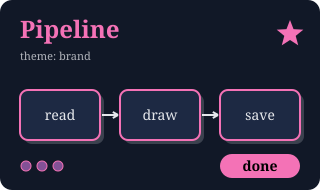

In [3]:
brand = svg.themes.get("dark").replace(
    name="brand",
    palette={
        "primary": "#f472b6",
        "on_primary": "=readable({palette.primary})",
        "surface": "=lighten({palette.background}, 0.08)",
        "accent": "=mix({palette.primary}, {palette.background}, 0.4, 'oklch')",
    },
    fonts={"family": "Georgia, serif"},
    roles={"box": {"stroke": "{palette.primary}", "stroke-width": "=max(2, {fonts.sizes.text} / 8)"}},
)
card(brand)

Themes can live in TOML text files. Changing a theme read from a file keeps its comments and only
rewrites the values you changed.

# Night: sky blue on the dark theme
name = "dusk"
extends = "dark"

[palette]
primary = "#f59e0b"   # sky
on_primary = "=readable({palette.primary})"
accent = "{palette.primary}"

[roles.title]
fill = "{palette.primary}"
font-size = "={fonts.sizes.title} * 1.1"



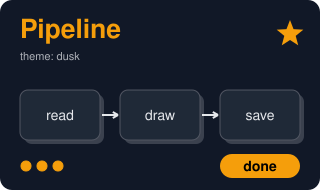

In [4]:
NIGHT = """# Night: sky blue on the dark theme
name = "night"
extends = "dark"

[palette]
primary = "#38bdf8"   # sky
on_primary = "=readable({palette.primary})"
accent = "{palette.primary}"

[roles.title]
fill = "{palette.primary}"
font-size = "={fonts.sizes.title} * 1.1"
"""
night = svg.Theme.from_toml(NIGHT)
dusk = night.replace(name="dusk", palette={"primary": "#f59e0b"})
print(dusk.to_toml())
card(dusk)

`with theme:` makes a theme the default for every document created inside the block.

In [5]:
with svg.themes.get("paper"):
    default = svg.Document(120, 40)
default.theme.name

'paper'

Save the brand theme as TOML and the drawing in it. Next: [20 Logo](../20_logo/logo.py).

In [6]:
if __name__ == "__main__":
    brand.save("19_brand.toml")
    card(brand).save("19_brand.svg")
    card(dusk).save("19_dusk.svg")